# NASA Space Explorer — Exploratory Data Analysis

Northwestern MLDS 400 · Data Engineering Project

A SQL-led exploration of the NASA Image and Video Library metadata in our local PostgreSQL database.

---
### 1. Introduction

Our pipeline moves NASA API search results through collection, normalization, and quality checks into PostgreSQL, where the EDA and Streamlit dashboard use them. This notebook examines the **current collected image metadata**.

The image table stores one row per `(source_api, source_id)`. A separate table stores image–search-topic relationships, so one image can match several topics. Mars and Earth were recently expanded using year-filtered requests; API inconsistencies and ID collisions still limit coverage.

We use four questions to understand the dataset before building dashboard views:

1. How are collected records distributed across search topics?
2. How are unique records distributed over time?
3. Which topics share the most unique images?
4. Which metadata fields are available, and which are often missing?

Counts, percentages, and findings are calculated from PostgreSQL rather than entered as fixed analysis values.

---
### 2. Setup & Database Connection

Run this notebook with the **nasa-space-explorer** Conda kernel, from either the project root or `notebooks/`. We load the project's `.env` explicitly and never display the connection URL. The libraries below handle SQL aggregation, small result tables, and interactive charts.

In [2]:
# Import the libraries used throughout the report.
import os
import sys
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from dotenv import load_dotenv
from IPython.display import Markdown, display
from sqlalchemy import create_engine, text

# Locate the repository from either supported notebook working directory.
working_directory = Path.cwd().resolve()
project_root = next(
    (path for path in [working_directory, *working_directory.parents]
     if (path / "src/database/db.py").is_file() and (path / ".env").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from the project root or notebooks directory; the root .env is required.")
load_dotenv(dotenv_path=project_root / ".env", override=False)
if not os.environ.get("DATABASE_URL"):
    raise RuntimeError("DATABASE_URL is missing. Configure the project's local .env file.")
if Path(sys.prefix).name != "nasa-space-explorer":
    raise RuntimeError("Select the nasa-space-explorer Conda kernel before running all cells.")

# VS Code uses this MIME type to render Plotly figures interactively.
pio.renderers.default = "plotly_mimetype"
print(f"Python {sys.version.split()[0]} · environment: {Path(sys.prefix).name}")

Python 3.11.18 · environment: nasa-space-explorer


We use the same PostgreSQL connection variable as the project modules. A repeatable-read, read-only transaction keeps every chart on the same snapshot and prevents accidental data writes. The cutoff for future dates is PostgreSQL's current date in America/Chicago.

In [3]:
# Keep the database read-only, including any queries added during exploration.
engine = create_engine(
    os.environ["DATABASE_URL"],
    isolation_level="REPEATABLE READ",
    connect_args={"options": "-c default_transaction_read_only=on -c timezone=America/Chicago"},
    hide_parameters=True,
)
connection = engine.connect()
snapshot = connection.begin()
connection_check = pd.read_sql(text("""
    SELECT CURRENT_DATE::text AS analysis_date,
           current_setting('transaction_read_only') AS read_only,
           current_setting('transaction_isolation') AS isolation_level
"""), connection)
assert connection_check.loc[0, "read_only"] == "on"
assert connection_check.loc[0, "isolation_level"] == "repeatable read"
as_of_date = connection_check.loc[0, "analysis_date"]
print(f"PostgreSQL connected · read-only snapshot · analysis date: {as_of_date}")

PostgreSQL connected · read-only snapshot · analysis date: 2026-11-22


The four charts share a navy and muted-blue theme, white backgrounds, and consistent typography. Summary tables use the same colors. These settings affect presentation only.

In [4]:
# Define one visual style for all four insights.
NAVY = "#18334F"
BLUE = "#527C9F"
PALE_BLUE = "#EEF3F8"
GRID = "#E5EBF1"
pio.templates["nasa_eda"] = go.layout.Template(layout=go.Layout(
    template="plotly_white",
    font=dict(family="Arial, sans-serif", size=13, color=NAVY),
    title=dict(x=0, xanchor="left", font=dict(size=20, color=NAVY)),
    paper_bgcolor="white", plot_bgcolor="white",
    colorway=[BLUE, NAVY],
    margin=dict(l=90, r=70, t=100, b=65),
    xaxis=dict(gridcolor=GRID, zeroline=False),
    yaxis=dict(gridcolor=GRID, zeroline=False),
    hoverlabel=dict(bgcolor="white", font_size=13),
))
pio.templates.default = "nasa_eda"
CHART_CONFIG = {"displaylogo": False, "responsive": True, "scrollZoom": False}
TABLE_STYLE = [
    {"selector": "th", "props": [("background-color", NAVY), ("color", "white"),
                                  ("padding", "9px 13px"), ("text-align", "left")]},
    {"selector": "td", "props": [("padding", "8px 13px"), ("border-bottom", "1px solid #E5EBF1")]},
    {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#F5F8FB")]},
    {"selector": "table", "props": [("border-collapse", "collapse"),
                                     ("font-family", "Arial, sans-serif"), ("font-size", "13px")]},
]

---
### 3. Dataset Overview & Data Profiling

We first inspect the real schema, then aggregate the image table and relationship table independently. The analysis scope is `source_api = 'nasa_library'` and `media_type = 'image'`. No image records are downloaded into Pandas in bulk.

In [5]:
# Inspect the actual schema instead of assuming optional fields exist.
schema = pd.read_sql(text("""
    SELECT table_name, column_name, data_type, is_nullable
    FROM information_schema.columns
    WHERE table_schema = 'public'
      AND table_name IN ('nasa_records', 'nasa_search_matches')
    ORDER BY table_name, ordinal_position
"""), connection)
required_fields = {"source_api", "source_id", "title", "date", "media_type", "image_url",
                   "explanation", "credit", "center", "location", "keywords"}
record_schema = schema.loc[schema["table_name"].eq("nasa_records")]
assert required_fields <= set(record_schema["column_name"])
assert record_schema.set_index("column_name").loc["date", "data_type"] == "date"
assert record_schema.set_index("column_name").loc["keywords", "data_type"] == "jsonb"
print(f"Schema verified: {len(record_schema)} image fields; date is DATE and keywords is JSONB.")

Schema verified: 14 image fields; date is DATE and keywords is JSONB.


The profile separates structural checks from metadata availability. PostgreSQL's `DATE` type rejects malformed calendar strings at storage time; we still check for NULL and non-finite dates. A future date is a separate anomaly, not a missing value.

In [6]:
# Calculate the image profile without joining and multiplying image rows.
profile_sql = """
SELECT COUNT(*) AS total_images,
       COUNT(DISTINCT (source_api, source_id)) AS unique_image_keys,
       MIN(date) FILTER (WHERE isfinite(date))::text AS earliest_date,
       MAX(date) FILTER (WHERE isfinite(date))::text AS latest_date,
       MIN(date) FILTER (WHERE isfinite(date) AND date <= CURRENT_DATE)::text AS historical_start,
       MAX(date) FILTER (WHERE isfinite(date) AND date <= CURRENT_DATE)::text AS historical_end,
       COUNT(*) FILTER (WHERE date IS NULL) AS missing_dates,
       COUNT(*) FILTER (WHERE NOT isfinite(date)) AS nonfinite_dates,
       COUNT(*) FILTER (WHERE isfinite(date) AND date > CURRENT_DATE) AS future_dates,
       COUNT(*) FILTER (WHERE isfinite(date) AND date <= CURRENT_DATE) AS historical_images,
       COUNT(*) FILTER (WHERE NOT COALESCE(title ~ '[^[:space:]]', FALSE)) AS missing_titles,
       COUNT(*) FILTER (WHERE title = 'Untitled NASA Image') AS placeholder_titles,
       COUNT(*) FILTER (WHERE NOT COALESCE(image_url ~ '[^[:space:]]', FALSE)) AS missing_image_urls
FROM nasa_records
WHERE source_api = 'nasa_library' AND media_type = 'image'
"""
profile = pd.read_sql(text(profile_sql), connection).iloc[0]

# Check relationship totals and integrity using the full source key.
relationship_profile = pd.read_sql(text("""
    SELECT COUNT(*) AS relationships,
           COUNT(DISTINCT (m.source_api, m.source_id, m.search_keyword)) AS unique_relationships,
           COUNT(DISTINCT m.search_keyword) AS search_topics
    FROM nasa_search_matches AS m
    JOIN nasa_records AS r USING (source_api, source_id)
    WHERE r.source_api = 'nasa_library' AND r.media_type = 'image'
"""), connection).iloc[0]
orphan_count = connection.execute(text("""
    SELECT COUNT(*) FROM nasa_search_matches AS m
    LEFT JOIN nasa_records AS r USING (source_api, source_id)
    WHERE r.source_id IS NULL
""")).scalar_one()
total_images = int(profile["total_images"])
total_relationships = int(relationship_profile["relationships"])
assert total_images > 0
assert total_images == profile["unique_image_keys"]
assert total_relationships == relationship_profile["unique_relationships"]
assert orphan_count == 0

overview = pd.DataFrame({
    "Dataset Measure": ["Unique images", "Image–topic relationships", "Search topics",
                        "Earliest stored date", "Latest stored date", "Historical dates used",
                        "Analysis cutoff (America/Chicago)"],
    "Value": [f"{total_images:,}", f"{total_relationships:,}",
              str(int(relationship_profile["search_topics"])),
              profile["earliest_date"], profile["latest_date"],
              f"{profile['historical_start']} to {profile['historical_end']}", as_of_date],
})
display(overview.style.hide(axis="index").set_table_styles(TABLE_STYLE))
quality_profile = pd.DataFrame({
    "Check": ["Missing or blank titles", "Normalized placeholder titles", "Missing or blank image URLs",
              "NULL dates", "Non-finite dates", "Future-dated records", "Orphan topic relationships"],
    "Records": [int(profile["missing_titles"]), int(profile["placeholder_titles"]),
                int(profile["missing_image_urls"]), int(profile["missing_dates"]),
                int(profile["nonfinite_dates"]), int(profile["future_dates"]), int(orphan_count)],
})
display(quality_profile.style.format({"Records": "{:,.0f}"}).hide(axis="index").set_table_styles(TABLE_STYLE))

Dataset Measure,Value
Unique images,"73,937"
Image–topic relationships,"80,809"
Search topics,9
Earliest stored date,1912-03-23
Latest stored date,2031-07-24
Historical dates used,1912-03-23 to 2026-11-17
Analysis cutoff (America/Chicago),2026-11-22


Check,Records
Missing or blank titles,0
Normalized placeholder titles,15
Missing or blank image URLs,0
NULL dates,0
Non-finite dates,0
Future-dated records,7
Orphan topic relationships,0


The extra relationship rows do not imply duplicate image rows. An image can match both Earth and Mars, for example, and remain a single image record. A stored URL is counted as available without testing whether the remote resource still loads.

The placeholder `Untitled NASA Image` was introduced during normalization. A nonblank placeholder makes the stored title field complete without restoring the original title. The original-title flag is not stored in the database, so we report the recognizable placeholder separately.

To investigate future dates, we inspect the small anomalous subset rather than changing the records.

In [7]:
# Retain the exact metadata values and show a small, reproducible anomaly sample.
future_records = pd.read_sql(text("""
    SELECT source_id, date::text AS stored_date, title
    FROM nasa_records
    WHERE source_api = 'nasa_library' AND media_type = 'image'
      AND isfinite(date) AND date > CURRENT_DATE
    ORDER BY date DESC, source_id
    LIMIT 10
"""), connection)
future_examples = future_records.rename(columns={"source_id": "NASA ID", "stored_date": "Stored Date", "title": "Title"})
display(future_examples.style.hide(axis="index").set_table_styles(TABLE_STYLE))
display(Markdown(
    f"**Date-quality note.** There are **{int(profile['future_dates']):,} future-dated records** as of {as_of_date}. "
    "The displayed KSC IDs contain earlier calendar dates than the stored metadata dates. "
    "This suggests metadata anomalies, but an ID alone is not enough to establish a corrected date. "
    "We retain all rows and exclude future dates only from the historical trend."
))

NASA ID,Stored Date,Title
KSC-20240724-PH-CSH01_0001,2031-07-24,Artemis II Core Stage Offload
KSC-20221116-PH-CLC03_0055,2029-11-16,Artemis I Liftoff
KSC-20221116-PH-CLC03_0057,2029-11-16,Artemis I Liftoff
KSC-20221116-PH-CLC03_0061,2029-11-16,Artemis I Liftoff
KSC-20200729-PH-ILW01_0004,2027-07-29,Mars 2020 NASA Administrator Briefing
KSC-20200729-PH-ILW01_0007,2027-07-29,Mars 2020 NASA Administrator Briefing
KSC-20200729-PH-ILW01_0008,2027-07-29,Mars 2020 NASA Administrator Briefing


**Date-quality note.** There are **7 future-dated records** as of 2026-11-22. The displayed KSC IDs contain earlier calendar dates than the stored metadata dates. This suggests metadata anomalies, but an ID alone is not enough to establish a corrected date. We retain all rows and exclude future dates only from the historical trend.

---
### 4. Insight 1 — Image Distribution by Search Topic

#### A. Research Question
How are the collected NASA image records distributed across the nine search topics?

#### B. Approach
We join the relationship table to the image table on the full source key, then count distinct matched images per topic. Pandas adds shares and presentation labels. A topic share uses **all topic relationships** as its denominator; an image share uses **unique images** and can sum to more than 100% across topics.

#### C. SQL Query & Data Preparation
This extends the original topic-count query with explicit scope and distinct-image counting.

In [12]:
# Reuse the original topic aggregation, now against the expanded database.
topic_sql = """
SELECT m.search_keyword AS topic,
       COUNT(DISTINCT (r.source_api, r.source_id)) AS topic_matches
FROM nasa_records AS r
JOIN nasa_search_matches AS m
  ON r.source_api = m.source_api AND r.source_id = m.source_id
WHERE r.source_api = 'nasa_library' AND r.media_type = 'image'
GROUP BY m.search_keyword
ORDER BY topic_matches DESC, topic
"""
topic_counts = pd.read_sql(text(topic_sql), connection)
topic_counts["topic_label"] = topic_counts["topic"].str.title()
topic_counts["match_share"] = topic_counts["topic_matches"] / total_relationships * 100
topic_counts["image_share"] = topic_counts["topic_matches"] / total_images * 100
assert topic_counts["topic_matches"].sum() == total_relationships

#### D. Summary Table
The two percentage columns answer different questions. The image-share column should not be interpreted as mutually exclusive categories.

In [13]:
topic_summary = topic_counts[["topic_label", "topic_matches", "match_share", "image_share"]].rename(columns={
    "topic_label": "Search Topic", "topic_matches": "Topic Matches",
    "match_share": "Share of All Matches", "image_share": "Share of Unique Images",
})
display(topic_summary.style.format({"Topic Matches": "{:,.0f}", "Share of All Matches": "{:.1f}%",
                                    "Share of Unique Images": "{:.1f}%"})
        .hide(axis="index").set_table_styles(TABLE_STYLE))

Search Topic,Topic Matches,Share of All Matches,Share of Unique Images
Earth,"41,211",51.0%,55.7%
Mars,"26,903",33.3%,36.4%
Saturn,"4,238",5.2%,5.7%
Mercury,"2,907",3.6%,3.9%
Jupiter,"2,639",3.3%,3.6%
Galaxy,"1,748",2.2%,2.4%
Venus,786,1.0%,1.1%
Neptune,265,0.3%,0.4%
Uranus,112,0.1%,0.2%


#### E. Visualization
We keep the original horizontal bar chart, place the largest topic first, and show formatted counts on every bar. Hover gives each topic's share of all matches.

In [14]:
fig_topics = px.bar(
    topic_counts, x="topic_matches", y="topic_label", orientation="h",
    text="topic_matches", custom_data=["match_share"],
    title="<b>Earth and Mars dominate collected topic matches</b><br><sup>Keyword-search relationships · categories can overlap</sup>",
    labels={"topic_matches": "Image–topic matches", "topic_label": "Search topic"},
)
fig_topics.update_traces(
    marker_color=BLUE, texttemplate="%{x:,}", textposition="outside", cliponaxis=False,
    hovertemplate="<b>%{y}</b><br>Matches: %{x:,}<br>Share of all matches: %{customdata[0]:.1f}%<extra></extra>",
)
fig_topics.update_yaxes(autorange="reversed", title=None, showgrid=False)
fig_topics.update_xaxes(range=[0, topic_counts["topic_matches"].max() * 1.18], tickformat=",d")
fig_topics.update_layout(height=520, showlegend=False)
fig_topics.show(config=CHART_CONFIG)


#### F. Key Finding

In our collected dataset, **Earth has the most topic matches (41,211)**, followed by **Mars (26,903)**. Together, these two topics account for **84.3% of all topic relationships**, while **Uranus has the fewest matches (112)**.


#### G. Interpretation & Limitations

The distribution is highly uneven, with Earth and Mars making up 84.3% of all topic matches. This means our dataset is much more concentrated on these two topics, while planets like Uranus and Neptune have far fewer records available for exploration. This imbalance is important because it may affect topic comparisons and make some planets appear more prominent in our analysis and dashboard.

However, these counts reflect NASA keyword-search results, not the actual number of photographs NASA has taken of each planet. Search results can also include spacecraft, missions, launches, and other related events. Additionally, some images appear under multiple topics, and differences in API coverage and search results may influence the distribution. Therefore, we should interpret these findings as patterns within our collected dataset rather than the complete NASA image archive.

---
### 5. Insight 2 — Historical Image Distribution

#### A. Research Question
How are unique records distributed over the metadata date field, and which years have the largest collected cohorts?

#### B. Approach
We aggregate `nasa_records` directly, without a topic join, so each unique image contributes once. SQL excludes NULL, non-finite, and future dates from this trend. Pandas fills missing calendar years with zero so the line does not imply uninterrupted annual coverage.

#### C. SQL Query & Data Preparation
The profile reports the full stored date range. The historical series below uses only dates on or before the analysis cutoff.

In [11]:
annual_sql = """
SELECT EXTRACT(YEAR FROM date)::integer AS year, COUNT(*) AS unique_images
FROM nasa_records
WHERE source_api = 'nasa_library' AND media_type = 'image'
  AND date IS NOT NULL AND isfinite(date) AND date <= CURRENT_DATE
GROUP BY EXTRACT(YEAR FROM date)::integer
ORDER BY year
"""
annual_counts = pd.read_sql(text(annual_sql), connection)
assert not annual_counts.empty
annual_counts = (annual_counts.set_index("year")
    .reindex(range(int(annual_counts["year"].min()), int(annual_counts["year"].max()) + 1), fill_value=0)
    .rename_axis("year").reset_index())
historical_total = int(annual_counts["unique_images"].sum())
assert historical_total == profile["historical_images"]
annual_counts["share"] = annual_counts["unique_images"] / historical_total * 100
annual_counts["period_note"] = annual_counts["year"].map(
    lambda year: f"Year to date through {as_of_date}" if year == int(as_of_date[:4]) else "Stored metadata year"
)
peak_year = annual_counts.sort_values(["unique_images", "year"], ascending=[False, True]).iloc[0]

#### D. Summary Table
The ten largest annual cohorts summarize the peaks; the chart keeps the full eligible year range. The current year is incomplete and should not be compared as a full year.

In [12]:
annual_summary = annual_counts.nlargest(10, "unique_images")[["year", "unique_images", "share", "period_note"]].rename(columns={
    "year": "Year", "unique_images": "Unique Images", "share": "Share of Historical Records", "period_note": "Date Note",
})
display(annual_summary.style.format({"Year": "{:d}", "Unique Images": "{:,.0f}",
                                     "Share of Historical Records": "{:.1f}%"})
        .hide(axis="index").set_table_styles(TABLE_STYLE))

Year,Unique Images,Share of Historical Records,Date Note
2014,"4,814",6.5%,Stored metadata year
2011,"4,451",6.0%,Stored metadata year
2013,"4,353",5.9%,Stored metadata year
2017,"3,933",5.3%,Stored metadata year
2012,"3,337",4.5%,Stored metadata year
2009,"2,901",3.9%,Stored metadata year
2018,"2,890",3.9%,Stored metadata year
2004,"2,774",3.8%,Stored metadata year
2020,"2,688",3.6%,Stored metadata year
2026,"2,582",3.5%,Year to date through 2026-11-22


#### E. Visualization
The full historical period is visible by default. Use the range slider to inspect the modern archive more closely. The highlighted point marks the largest annual cohort.

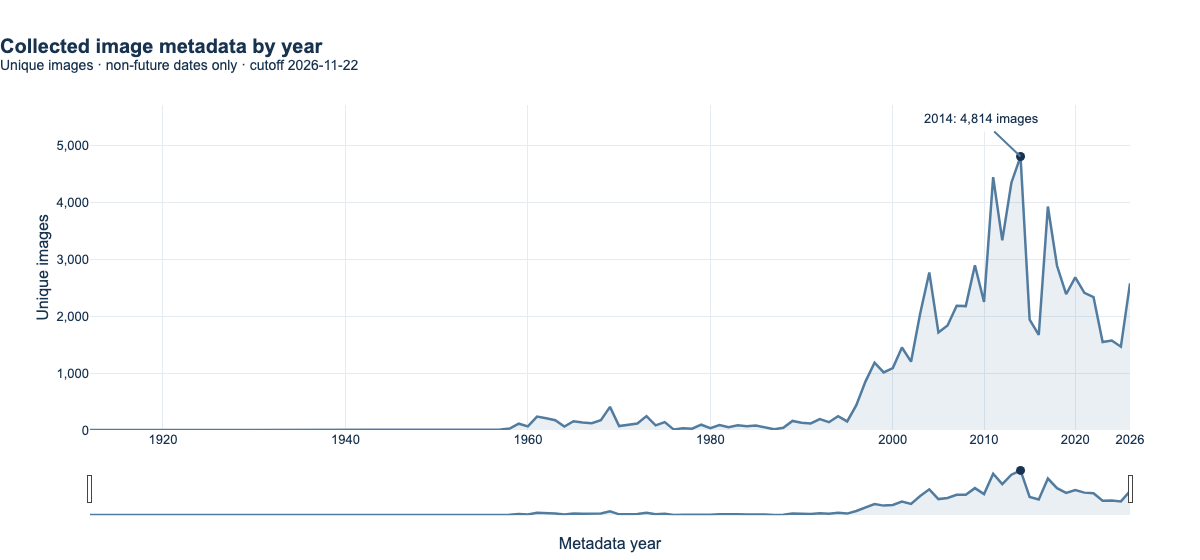

In [13]:
fig_history = px.line(
    annual_counts, x="year", y="unique_images", custom_data=["share", "period_note"],
    title=f"<b>Collected image metadata by year</b><br><sup>Unique images · non-future dates only · cutoff {as_of_date}</sup>",
    labels={"year": "Metadata year", "unique_images": "Unique images"},
)
fig_history.update_traces(
    line=dict(color=BLUE, width=2.5), fill="tozeroy", fillcolor="rgba(82,124,159,0.12)",
    hovertemplate="<b>%{x:.0f}</b><br>Unique images: %{y:,}<br>Share: %{customdata[0]:.1f}%<br>%{customdata[1]}<extra></extra>",
)
fig_history.add_scatter(x=[int(peak_year["year"])], y=[int(peak_year["unique_images"])],
                        mode="markers", marker=dict(color=NAVY, size=9), showlegend=False,
                        hoverinfo="skip")
fig_history.add_annotation(x=int(peak_year["year"]), y=int(peak_year["unique_images"]),
    text=f"{int(peak_year['year'])}: {int(peak_year['unique_images']):,} images",
    showarrow=True, arrowhead=0, arrowcolor=BLUE, ax=-40, ay=-38,
    bgcolor="white", borderpad=5, font=dict(color=NAVY))
# Label the final data year explicitly while keeping the full historical span.
fig_history.update_xaxes(
    tickformat="d", tickmode="array",
    tickvals=[1920, 1940, 1960, 1980, 2000, 2010, 2020, 2026],
    tickangle=0,
    rangeslider=dict(visible=True, thickness=0.13),
)
fig_history.update_yaxes(tickformat=",d", rangemode="tozero")
fig_history.update_layout(height=560, showlegend=False, margin=dict(t=105, b=45))
fig_history.show(config=CHART_CONFIG)

#### F. Key Finding

The historical analysis covers **73,930 unique images**, with metadata dates ranging from 1912 to 2026. The largest number of records appears in **2014, with 4,814 images (6.5%)**.

Overall, **89.3% of the records are dated 2000 or later**, showing that our collected dataset is heavily concentrated in more recent decades.

#### G. Interpretation & Limitations

The historical distribution shows a clear concentration of image records in recent decades, especially after 2000. This suggests that our collected dataset provides much stronger coverage of more recent years, while older records are relatively limited. The noticeable peak in 2014 also shows that image records are not evenly distributed over time. For our analysis and Streamlit Dashboard, this means users are more likely to find images from recent decades, while searches for earlier years may return fewer results.

However, this pattern does not necessarily mean NASA took more photographs during these years. The distribution may be influenced by mission coverage, archival practices, keyword searches, and the dates recorded in the metadata. Additionally, 2026 is only a partial year, so it should not be directly compared with complete years. The 7 future-dated records were excluded from the historical analysis to avoid misleading trends, but remain unchanged in the original database.

---
### 6. Insight 3 — Topic Overlap Analysis

#### A. Research Question
Which search topics share the most unique images, and how common are multi-topic images?

#### B. Approach
A distinct relationship CTE removes duplicate join combinations. A self-join on the image key, with `topic_a < topic_b`, counts each unordered pair once per image. A second SQL aggregation counts topics per image, including any image with no topic. Pandas constructs a symmetric matrix and adds size-adjusted pair summaries.

#### C. SQL Query & Data Preparation
The matrix diagonal holds each topic's own image count. Off-diagonal cells hold shared unique images; an image matching three topics contributes to three different pairs.

In [15]:
overlap_sql = """
WITH matches AS (
    SELECT DISTINCT m.source_api, m.source_id, m.search_keyword
    FROM nasa_search_matches AS m
    JOIN nasa_records AS r USING (source_api, source_id)
    WHERE r.source_api = 'nasa_library' AND r.media_type = 'image'
)
SELECT a.search_keyword AS topic_a, b.search_keyword AS topic_b,
       COUNT(*) AS shared_images
FROM matches AS a
JOIN matches AS b
  ON a.source_api = b.source_api AND a.source_id = b.source_id
 AND a.search_keyword < b.search_keyword
GROUP BY a.search_keyword, b.search_keyword
ORDER BY shared_images DESC, topic_a, topic_b
"""
pair_counts = pd.read_sql(text(overlap_sql), connection)
image_multiplicity = pd.read_sql(text("""
    WITH topics_per_image AS (
        SELECT r.source_api, r.source_id, COUNT(DISTINCT m.search_keyword) AS topic_count
        FROM nasa_records AS r
        LEFT JOIN nasa_search_matches AS m USING (source_api, source_id)
        WHERE r.source_api = 'nasa_library' AND r.media_type = 'image'
        GROUP BY r.source_api, r.source_id
    )
    SELECT topic_count, COUNT(*) AS unique_images
    FROM topics_per_image GROUP BY topic_count ORDER BY topic_count
"""), connection)
assert image_multiplicity["unique_images"].sum() == total_images
assert (image_multiplicity["topic_count"] * image_multiplicity["unique_images"]).sum() == total_relationships

# Use the same ordering as the topic-distribution chart.
topic_order = topic_counts["topic"].tolist()
topic_totals = topic_counts.set_index("topic")["topic_matches"]
overlap_matrix = pd.DataFrame(0, index=topic_order, columns=topic_order, dtype="int64")
for topic in topic_order:
    overlap_matrix.loc[topic, topic] = int(topic_totals[topic])
for row in pair_counts.itertuples(index=False):
    overlap_matrix.loc[row.topic_a, row.topic_b] = row.shared_images
    overlap_matrix.loc[row.topic_b, row.topic_a] = row.shared_images
assert overlap_matrix.equals(overlap_matrix.T)
pair_counts["a_images"] = pair_counts["topic_a"].map(topic_totals)
pair_counts["b_images"] = pair_counts["topic_b"].map(topic_totals)
pair_counts["smaller_topic_share"] = pair_counts["shared_images"] / pair_counts[["a_images", "b_images"]].min(axis=1) * 100
pair_counts["jaccard"] = pair_counts["shared_images"] / (
    pair_counts["a_images"] + pair_counts["b_images"] - pair_counts["shared_images"]) * 100

#### D. Summary Table
The table ranks shared-image counts. “Share of Smaller Topic” gives context for unequal topic sizes; Jaccard is shared images divided by the two-topic union. Neither percentage is a measure of visual similarity.

In [16]:
pair_summary = pair_counts.head(10).copy()
pair_summary["Topic Pair"] = pair_summary["topic_a"].str.title() + " / " + pair_summary["topic_b"].str.title()
pair_summary = pair_summary[["Topic Pair", "shared_images", "smaller_topic_share", "jaccard"]].rename(columns={
    "shared_images": "Shared Unique Images", "smaller_topic_share": "Share of Smaller Topic", "jaccard": "Jaccard Overlap",
})
display(pair_summary.style.format({"Shared Unique Images": "{:,.0f}", "Share of Smaller Topic": "{:.1f}%",
                                   "Jaccard Overlap": "{:.1f}%"})
        .hide(axis="index").set_table_styles(TABLE_STYLE))

Topic Pair,Shared Unique Images,Share of Smaller Topic,Jaccard Overlap
Earth / Mars,"3,699",13.7%,5.7%
Earth / Galaxy,688,39.4%,1.6%
Earth / Saturn,533,12.6%,1.2%
Earth / Jupiter,398,15.1%,0.9%
Earth / Mercury,356,12.2%,0.8%
Jupiter / Mars,332,12.6%,1.1%
Earth / Venus,308,39.2%,0.7%
Jupiter / Saturn,222,8.4%,3.3%
Mercury / Venus,172,21.9%,4.9%
Mars / Venus,121,15.4%,0.4%


#### E. Visualization
**Gray diagonal cells show topic totals; blue off-diagonal cells show shared unique images.** The blue color scale is linear from zero to the largest shared count. Separating diagonal totals keeps them from washing out the overlap cells; exact values remain visible throughout.

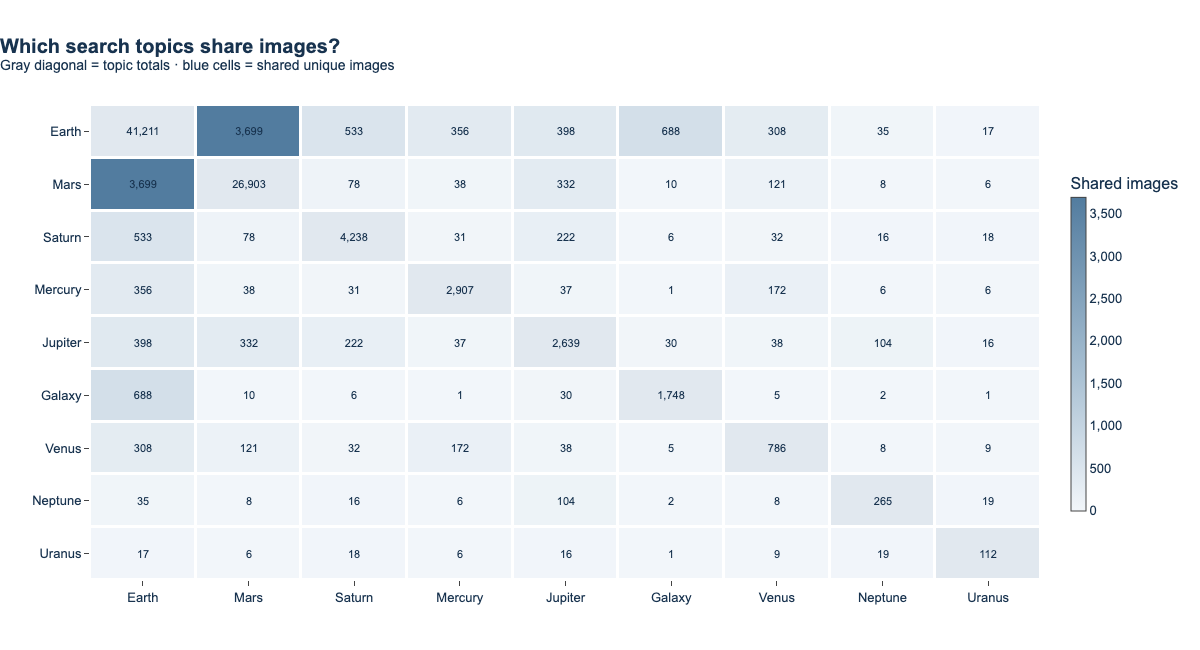

In [17]:
matrix_labels = [topic.title() for topic in topic_order]
shared_values = [[None if a == b else int(overlap_matrix.loc[a, b]) for b in topic_order] for a in topic_order]
diagonal_values = [[int(overlap_matrix.loc[a, b]) if a == b else None for b in topic_order] for a in topic_order]
max_shared = int(pair_counts["shared_images"].max()) if not pair_counts.empty else 0
fig_overlap = go.Figure()
fig_overlap.add_trace(go.Heatmap(
    z=shared_values, x=matrix_labels, y=matrix_labels, zmin=0, zmax=max(1, max_shared),
    colorscale=[[0, "#F2F6FA"], [0.45, "#A6BED1"], [1, "#527C9F"]],
    texttemplate="%{z:,}", textfont=dict(size=11, color=NAVY), xgap=3, ygap=3,
    colorbar=dict(title="Shared images", tickformat=",d", thickness=15, len=0.75),
    hoverongaps=False,
    hovertemplate="<b>%{y} / %{x}</b><br>Shared unique images: %{z:,}<extra></extra>",
))
fig_overlap.add_trace(go.Heatmap(
    z=diagonal_values, x=matrix_labels, y=matrix_labels,
    colorscale=[[0, "#E1E8EF"], [1, "#E1E8EF"]], showscale=False,
    texttemplate="%{z:,}", textfont=dict(size=11, color=NAVY), xgap=3, ygap=3,
    hoverongaps=False,
    hovertemplate="<b>%{y}</b><br>Topic total: %{z:,}<br>Diagonal: not an additional overlap<extra></extra>",
))
fig_overlap.update_layout(
    title="<b>Which search topics share images?</b><br><sup>Gray diagonal = topic totals · blue cells = shared unique images</sup>",
    height=650, margin=dict(l=90, r=120, t=105, b=70),
    xaxis=dict(title=None, side="bottom", tickangle=0, showgrid=False),
    yaxis=dict(title=None, autorange="reversed", showgrid=False),
)
fig_overlap.show(config=CHART_CONFIG)


#### F. Key Finding

In our collected dataset, **6,482 unique images (8.8%)** are associated with two or more search topics, meaning most images belong to only one of our nine topics.

**Earth and Mars have the highest overlap, sharing 3,699 images**. However, these shared images represent only **13.7% of Mars records** (the smaller topic) and a **5.7% Jaccard similarity**, indicating that their overall overlap is relatively limited.



#### G. Interpretation & Limitations

Although Earth and Mars share the largest number of images, their relatively low Jaccard similarity (5.7%) shows that most records in these two topics are still different. Overall, only 8.8% of our unique images appear under multiple search topics, suggesting that the majority of records are associated with a single topic in our dataset.

This finding is important for our analysis and Streamlit Dashboard because selecting multiple topics could return the same image more than once. Using unique NASA IDs helps us avoid double-counting while still preserving all relevant topic relationships.

However, topic overlap is based on NASA keyword-search results, not the actual visual content of each image. A record may match multiple topics because of its title, description, mission, or related events. Therefore, shared topic labels do not necessarily mean an image directly depicts both planets.


---
### 7. Insight 4 — Metadata Completeness

#### A. Research Question
Which stored metadata fields are available, and which commonly need fallbacks in the dashboard?

#### B. Approach
SQL counts available values in eight fields verified in the schema. For text, NULL, empty strings, and surrounding whitespace count as missing. A date is available if present and finite; future-date validity remains a separate check. Keywords are available only when the JSONB array contains at least one nonblank string.

#### C. SQL Query & Data Preparation
SQL performs the aggregation in PostgreSQL. The guarded JSONB expression avoids treating an empty array, JSON null, or a non-array value as usable keywords.

In [19]:
metadata_sql = """
SELECT COUNT(*) AS total_images,
       COUNT(*) FILTER (WHERE title ~ '[^[:space:]]') AS title,
       COUNT(*) FILTER (WHERE date IS NOT NULL AND isfinite(date)) AS date,
       COUNT(*) FILTER (WHERE image_url ~ '[^[:space:]]') AS image_url,
       COUNT(*) FILTER (WHERE explanation ~ '[^[:space:]]') AS explanation,
       COUNT(*) FILTER (WHERE credit ~ '[^[:space:]]') AS credit,
       COUNT(*) FILTER (WHERE center ~ '[^[:space:]]') AS center,
       COUNT(*) FILTER (WHERE location ~ '[^[:space:]]') AS location,
       COUNT(*) FILTER (WHERE CASE WHEN jsonb_typeof(keywords) = 'array' THEN
           EXISTS (SELECT 1 FROM jsonb_array_elements(keywords) AS keyword(value)
                   WHERE jsonb_typeof(value) = 'string'
                     AND (value #>> '{}') ~ '[^[:space:]]')
           ELSE FALSE END) AS keywords,
       COUNT(*) FILTER (WHERE keywords IS NOT NULL AND jsonb_typeof(keywords) <> 'array') AS non_array_keywords
FROM nasa_records
WHERE source_api = 'nasa_library' AND media_type = 'image'
"""
metadata_counts = pd.read_sql(text(metadata_sql), connection).iloc[0]
assert metadata_counts["total_images"] == total_images
field_labels = {"title": "Title", "date": "Date", "image_url": "Image URL", "explanation": "Explanation",
                "credit": "Credit", "center": "Center", "location": "Location", "keywords": "Keywords"}
metadata_summary = pd.DataFrame([
    {"field": field, "Metadata Field": label, "Available Records": int(metadata_counts[field])}
    for field, label in field_labels.items()
])
metadata_summary["Missing Records"] = total_images - metadata_summary["Available Records"]
metadata_summary["Completeness Percentage"] = metadata_summary["Available Records"] / total_images * 100
metadata_summary = metadata_summary.sort_values("Completeness Percentage", ascending=False, kind="stable").reset_index(drop=True)

#### D. Summary Table
The denominator is the unique-image count, not the larger relationship count. “Available” describes stored metadata and does not certify factual accuracy.

In [20]:
display(metadata_summary.drop(columns="field").style.format({
    "Available Records": "{:,.0f}", "Missing Records": "{:,.0f}", "Completeness Percentage": "{:.2f}%",
}).hide(axis="index").set_table_styles(TABLE_STYLE))

Metadata Field,Available Records,Missing Records,Completeness Percentage
Title,"73,937",0,100.00%
Date,"73,937",0,100.00%
Image URL,"73,937",0,100.00%
Explanation,"73,923",14,99.98%
Center,"73,895",42,99.94%
Keywords,"56,520","17,417",76.44%
Location,"34,605","39,332",46.80%
Credit,"23,746","50,191",32.12%


#### E. Visualization
A fixed 0–100% axis makes completeness comparable across fields. Extra right margin keeps the percentage labels outside full-length bars without changing that scale.

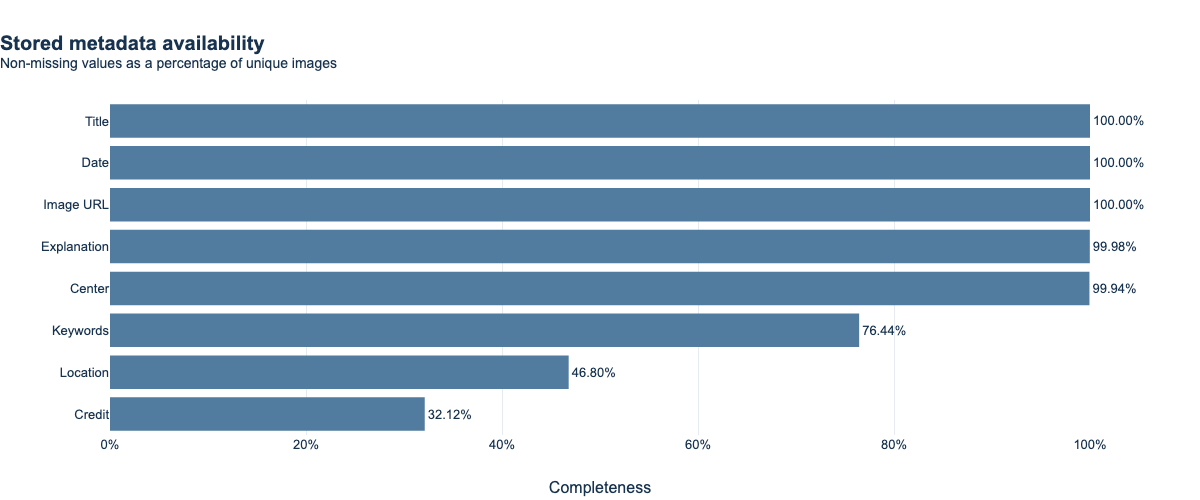

In [21]:
fig_metadata = px.bar(
    metadata_summary, x="Completeness Percentage", y="Metadata Field", orientation="h",
    custom_data=["Available Records", "Missing Records"],
    title="<b>Stored metadata availability</b><br><sup>Non-missing values as a percentage of unique images</sup>",
)
fig_metadata.update_traces(
    marker_color=BLUE, text=metadata_summary["Completeness Percentage"],
    texttemplate="%{text:.2f}%", textposition="outside", cliponaxis=False,
    hovertemplate="<b>%{y}</b><br>Available: %{customdata[0]:,}<br>Missing: %{customdata[1]:,}<br>Completeness: %{x:.2f}%<extra></extra>",
)
fig_metadata.update_xaxes(range=[0, 100], ticksuffix="%", dtick=20, title="Completeness")
fig_metadata.update_yaxes(autorange="reversed", title=None, showgrid=False)
fig_metadata.update_layout(height=500, margin=dict(l=110, r=110, t=100, b=65), showlegend=False)
fig_metadata.show(config=CHART_CONFIG)


#### F. Key Finding

All **73,937 image records** contain a Title, Date, and Image URL, giving these three fields **100% completeness**.

However, **Credit has the lowest completeness at 32.12% (23,746 records)**, followed by Location at **46.80%**. Usable Keywords are available for **76.44%** of the images.

Although Title and Date are fully populated, the dataset still contains **15 placeholder titles** and **7 future-dated records**, showing that complete fields are not always accurate or meaningful.



#### G. Interpretation & Limitations

The results show that our dataset has strong completeness in its core fields, making it suitable for displaying images with titles and dates. However, additional metadata is much less consistent. For example, photographer credits are missing from nearly two-thirds of the records, while location information is missing from more than half. This limits how much detail we can provide for some images.

These findings are important for our Streamlit Dashboard. We should handle missing optional fields gracefully, rather than displaying empty values or assuming every image has complete information. For example, unavailable credits and locations should be clearly indicated, and keyword-based filtering may not cover every image.

It is also important to distinguish completeness from accuracy. A field can contain a value but still be incorrect, as shown by the placeholder titles and future-dated records. Similarly, having an Image URL does not guarantee that the link is accessible. Missing optional metadata does not necessarily mean an image is invalid.


---

### 8. Overall Findings & Data Limitations

#### Overall Findings

Our EDA explored **73,937 unique NASA image records** and **80,809 image-topic relationships**. The four analyses highlight several important patterns in our collected dataset:

1. **Topic Distribution:** Earth (41,211) and Mars (26,903) account for **84.3% of all topic matches**, while Uranus has the fewest (112). This shows that our dataset is heavily concentrated on Earth and Mars, making topic representation uneven.

2. **Historical Distribution:** The largest number of records appears in **2014 (4,814 images)**, and **89.3% of historical records are dated 2000 or later**. Our dataset provides much stronger coverage of recent decades than earlier years.

3. **Topic Overlap:** **6,482 images (8.8%)** match multiple search topics. Earth and Mars share the most images (3,699), although their Jaccard similarity is only **5.7%**. This highlights the importance of avoiding duplicate image counts when analyzing multiple topics.

4. **Metadata Completeness:** Title, Date, and Image URL have **100% completeness**, but Credit is only **32.12% complete** and Location is **46.80% complete**. These differences show why our dashboard needs to handle missing optional metadata carefully.

Overall, these findings help us understand the dataset's strengths, limitations, and how we should design the Streamlit Dashboard to present the data accurately.



#### Data Limitations

Although our dataset is useful for exploration and analysis, several limitations should be considered:

- **API Coverage:** Mars and Earth were collected using year-based searches to work around NASA API pagination limits. Some API inconsistencies remain, especially for Earth, so we cannot guarantee complete coverage of all available search results.

- **Duplicate IDs:** Some distinct NASA assets share the same NASA ID. Since our database uses NASA IDs to identify unique records, these assets may be stored as a single record. Therefore, unique database records do not always represent distinct physical images.

- **Keyword Search Bias:** Images are grouped by search keywords, not verified visual content. Results may include spacecraft, missions, launches, and other related events rather than directly showing a planet.

- **Topic Overlap:** One image can belong to multiple search topics. Therefore, adding topic counts together does not give the total number of unique images.

- **Date Quality:** Metadata dates may not always reflect the actual capture date. We identified 7 future-dated records and excluded them from the historical trend analysis while preserving them in the database. The current year is also incomplete.

- **Missing Metadata:** Fields such as Credit and Location are often unavailable or not applicable. Additionally, a populated field does not necessarily mean its information is accurate, and stored image URLs have not all been checked for accessibility.

These limitations do not invalidate our analysis, but they help define what we can reasonably conclude from the collected data.


---
### 9. Conclusion

Through this EDA, we explored **73,937 unique NASA image records** and **80,809 image-topic relationships**, identifying important patterns in topic distribution, historical coverage, topic overlap, and metadata completeness.

Our findings show that the dataset is heavily concentrated on Earth and Mars, with most records coming from more recent decades. We also found that some images appear under multiple search topics, while optional metadata such as photographer credits and locations is often missing. These results help us better understand both the strengths and limitations of our collected data.

These insights will guide the development of our **Streamlit Dashboard**. We can use unique NASA IDs to avoid duplicate images, provide interactive topic and date filters, and handle missing metadata without affecting the user experience. We will also clearly communicate data coverage limitations so users can interpret the results appropriately.

Overall, this analysis provides a reliable foundation for turning our NASA data engineering pipeline into an interactive application that allows users to explore and better understand NASA's image archive.


### Final Validation

Before finishing, we run a final check to make sure our analysis results are consistent with the database and all four visualizations are valid.


In [24]:
# Reconcile analysis outputs against the live snapshot before closing it.
assert len(topic_counts) == int(relationship_profile["search_topics"])
assert topic_counts["topic_matches"].sum() == total_relationships
assert historical_total + int(profile["future_dates"]) + int(profile["missing_dates"]) + int(profile["nonfinite_dates"]) == total_images
assert image_multiplicity["unique_images"].sum() == total_images
assert all(int(overlap_matrix.loc[t, t]) == int(topic_totals[t]) for t in topic_order)
assert (metadata_summary["Available Records"] + metadata_summary["Missing Records"]).eq(total_images).all()
assert metadata_summary["Completeness Percentage"].between(0, 100).all()
assert all(int(row.shared_images) <= min(int(row.a_images), int(row.b_images)) for row in pair_counts.itertuples())
figures = [fig_topics, fig_history, fig_overlap, fig_metadata]
assert len(figures) == 4 and all(len(figure.data) > 0 for figure in figures)
for figure in figures:
    figure.to_json(validate=True)

# Roll back the read-only transaction and release the connection.
snapshot.rollback()
connection.close()
engine.dispose()
print(f"Validation passed: {total_images:,} unique images · {total_relationships:,} relationships · "
      f"{len(topic_counts)} topics · four Plotly figures. Read-only snapshot closed.")

Validation passed: 73,937 unique images · 80,809 relationships · 9 topics · four Plotly figures. Read-only snapshot closed.
